# 08 - Final analysis: does the geometric difference predict a quantum advantage? (week 3)
Owner: **Haider**

This notebook runs no new experiments. It reads the saved results of notebooks 01-07 and answers the research question with all evidence together:

1. **Best classical vs best quantum** (course guidance): $C^\ast$ is the classical SVM with the highest training-CV accuracy; $Q^\ast$ is chosen the same way among the two quantum kernels (fidelity, projected), with ties going to the projected kernel (fewer circuits). The gap $\Delta A^\ast = A^{Q^\ast} - A^{C^\ast}$ is judged by the same rule as before: an improvement only if its mean over seeds exceeds its standard deviation.
2. **$\Delta A$ against $g$** for every setting we ran: original labels, engineered labels, the noise model and the real-hardware run.
3. **One summary table** of all settings.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src.common import result_path, RESULTS, SEEDS

N_LIST = [2, 4, 6, 8]
LAMS = [("0p1", 0.1), ("0p01", 0.01), ("0p001", 0.001)]
load = lambda name, s, n: json.loads(result_path("tables", name, s, n, "json").read_text())
figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)

## 1. Collect every result

In [2]:
def pick_q(cands):
    """Q*: quantum kernel with the highest inner-CV score; ties go to the projected kernel."""
    return max(cands, key=lambda c: (c["cv"], c["name"] == "projected"))

real, eng = [], []
for n in N_LIST:
    for s in SEEDS:
        b, f, p = load("baselines_v2", s, n), load("fidelity_v2", s, n), load("projected_v2", s, n)
        gp, gf = load("geometry_projected_v2", s, n), load("geometry_fidelity_v2", s, n)
        acc_c = b["results"][b["c_star"]]["acc"]
        cands = [dict(name="fidelity", cv=f["best"]["score"], acc=f["sampled"]["acc"], g=gf["g_c_star"]),
                 dict(name="projected", cv=p["best"]["score"], acc=p["sampled"]["acc"], g=gp["g_c_star"])]
        q = pick_q(cands)
        real.append(dict(n=n, seed=s, acc_c=acc_c, acc_q=q["acc"], q=q["name"], dA=q["acc"] - acc_c,
                         dA_proj=gp["delta_A"], dA_fid=gf["delta_A"], g_proj=gp["g_c_star"], g_fid=gf["g_c_star"]))
        for tag, lam in LAMS:
            e = load(f"engineered_lam{tag}", s, n)
            cands = [dict(name="fidelity", cv=e["fidelity"]["best"]["score"], acc=e["fidelity"]["sampled"]["acc"]),
                     dict(name="projected", cv=e["projected"]["best"]["score"], acc=e["projected"]["sampled"]["acc"])]
            q = pick_q(cands)
            eng.append(dict(n=n, seed=s, lam=lam, acc_c=e["acc_c_star"], acc_q=q["acc"], q=q["name"],
                            dA=q["acc"] - e["acc_c_star"], dA_proj=e["delta_A"], dA_fid=e["delta_A_fidelity"],
                            g_proj=e["g_c_star"]))

noise = {k: [load(f"noise_{k}", s, n) for n in N_LIST for s in SEEDS] for k in ["projected", "fidelity"]}
for k in noise:
    for r in noise[k]:
        r["n"] = r["n_qubits"]
hw = load("hardware_projected", 0, 6)
hw_level = {r["level"]: r for r in hw["levels"]}
print(len(real), "original-label runs,", len(eng), "engineered-label runs,",
      len(noise["projected"]) + len(noise["fidelity"]), "noisy runs, 1 hardware run (seed 0, n=6)")

20 original-label runs, 60 engineered-label runs, 40 noisy runs, 1 hardware run (seed 0, n=6)


## 2. Best classical vs best quantum (each chosen by training CV)

labels                      n          C* acc          Q* acc          Delta A*   Q* picked   verdict
original labels             2    0.795 +-0.043    0.785 +-0.083     -0.010 +-0.115   proj 4/5    no improvement
original labels             4    0.820 +-0.051    0.765 +-0.034     -0.055 +-0.053   proj 2/5    no improvement
original labels             6    0.825 +-0.052    0.790 +-0.041     -0.035 +-0.044   proj 0/5    no improvement
original labels             8    0.840 +-0.064    0.810 +-0.075     -0.030 +-0.102   proj 1/5    no improvement

engineered, lambda=0.1      2    0.940 +-0.030    0.905 +-0.097     -0.035 +-0.072   proj 5/5    no improvement
engineered, lambda=0.1      4    0.845 +-0.040    0.855 +-0.073     +0.010 +-0.041   proj 5/5    no improvement
engineered, lambda=0.1      6    0.775 +-0.069    0.825 +-0.061     +0.050 +-0.035   proj 5/5    improvement
engineered, lambda=0.1      8    0.770 +-0.125    0.815 +-0.058     +0.045 +-0.091   proj 4/5    no improvement

eng

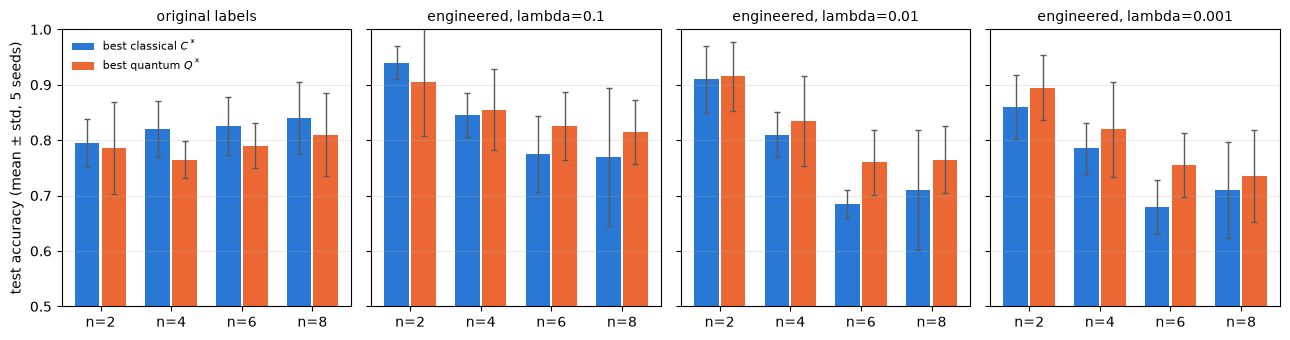

In [3]:
def ms(v):
    v = np.asarray(v, float)
    return v.mean(), v.std()

def verdict(d):
    m, s = ms(d)
    return "improvement" if m > s else "no improvement"

panels = [("original labels", real)] + [(f"engineered, lambda={lam:g}", [r for r in eng if r["lam"] == lam])
                                        for _, lam in LAMS]
print(f"{'labels':<26}{'n':>3}{'C* acc':>16}{'Q* acc':>16}{'Delta A*':>18}   Q* picked   verdict")
for title, rows in panels:
    for n in N_LIST:
        rs = [r for r in rows if r["n"] == n]
        mc, sc = ms([r["acc_c"] for r in rs]); mq, sq = ms([r["acc_q"] for r in rs])
        md_, sd = ms([r["dA"] for r in rs])
        picks = sum(r["q"] == "projected" for r in rs)
        print(f"{title:<26}{n:>3}{mc:>9.3f} +-{sc:.3f}{mq:>9.3f} +-{sq:.3f}{md_:>+11.3f} +-{sd:.3f}"
              f"   proj {picks}/5    {verdict([r['dA'] for r in rs])}")
    print()

x, w = np.arange(len(N_LIST)), 0.38
fig, axes = plt.subplots(1, len(panels), figsize=(13, 3.5), sharey=True)
for ax, (title, rows) in zip(axes, panels):
    for k, (key, lab, col) in enumerate([("acc_c", "best classical $C^*$", "#2a78d6"),
                                         ("acc_q", "best quantum $Q^*$", "#eb6834")]):
        m = [np.mean([r[key] for r in rows if r["n"] == n]) for n in N_LIST]
        s = [np.std([r[key] for r in rows if r["n"] == n]) for n in N_LIST]
        ax.bar(x + (k - 0.5) * w, m, w * 0.92, yerr=s, color=col, capsize=2,
               error_kw=dict(elinewidth=1, ecolor="0.35"), label=lab)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(x, [f"n={n}" for n in N_LIST])
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("test accuracy (mean $\\pm$ std, 5 seeds)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figdir / "final_best_classical_vs_best_quantum.png", dpi=200)
plt.show()

## 3. $\Delta A$ against $g$ for every setting

One point per seed and qubit count. $g = g_{\mathrm{gen}}(K^{C^\ast}\|K^Q)$ at $\lambda=0.1$ from ideal kernels (noisy kernels for the noise-model points, hardware features for the hardware point). Engineered labels are shown for the projected kernel, the kernel they were built from.

setting                                  points  mean g  mean dA  dA>0  r(g,dA)
projected, original                          20    3.18   -0.071     3    +0.12
fidelity, original                           20    3.01   -0.015     7    -0.01
projected, engineered (all 3 lambda)         60    3.02   +0.035    38    +0.11
projected, noise model                       20    3.15   -0.074     4    -0.04
fidelity, noise model                        20    2.70   -0.020     7    +0.21
projected, real hardware                      1    3.36   -0.100


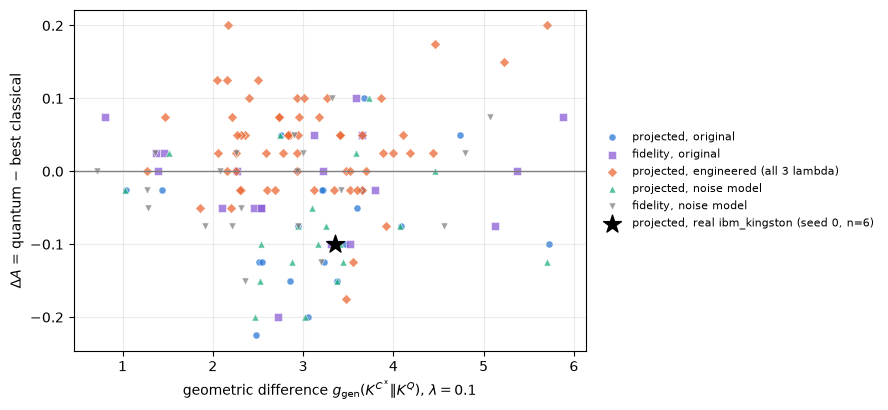

In [4]:
groups = [
    ("projected, original", [r["g_proj"] for r in real], [r["dA_proj"] for r in real], "#2a78d6", "o"),
    ("fidelity, original", [r["g_fid"] for r in real], [r["dA_fid"] for r in real], "#8a5cd6", "s"),
    ("projected, engineered (all 3 lambda)", [r["g_proj"] for r in eng], [r["dA_proj"] for r in eng], "#eb6834", "D"),
    ("projected, noise model", [r["g_noisy"] for r in noise["projected"]],
     [r["delta_A_noisy"] for r in noise["projected"]], "#1baf7a", "^"),
    ("fidelity, noise model", [r["g_noisy"] for r in noise["fidelity"]],
     [r["delta_A_noisy"] for r in noise["fidelity"]], "#7f7f7f", "v"),
]
hw_r = hw_level[f"real hardware ({hw['backend']})"]

print(f"{'setting':<40}{'points':>7}{'mean g':>8}{'mean dA':>9}{'dA>0':>6}{'r(g,dA)':>9}")
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, g, d, c, mk in groups:
    g, d = np.asarray(g), np.asarray(d)
    r = np.corrcoef(g, d)[0, 1]
    print(f"{name:<40}{len(g):>7}{g.mean():>8.2f}{d.mean():>+9.3f}{int((d > 0).sum()):>6}{r:>+9.2f}")
    ax.scatter(g, d, s=26, color=c, marker=mk, alpha=0.75, edgecolor="white", linewidth=0.5, label=name)
ax.scatter([hw_r["g"]], [hw_r["delta_A"]], s=180, color="black", marker="*", zorder=5,
           label="projected, real ibm_kingston (seed 0, n=6)")
print(f"{'projected, real hardware':<40}{1:>7}{hw_r['g']:>8.2f}{hw_r['delta_A']:>+9.3f}")
ax.axhline(0, color="0.5", linewidth=1)
ax.set_xlabel(r"geometric difference $g_{\mathrm{gen}}(K^{C^*}\|K^Q)$, $\lambda=0.1$")
ax.set_ylabel(r"$\Delta A$ = quantum $-$ best classical")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
fig.savefig(figdir / "final_deltaA_vs_g_all.png", dpi=200)
plt.show()

## 4. Summary

In [5]:
summary = dict(
    best_vs_best={title: {n: dict(acc_c=ms([r["acc_c"] for r in rows if r["n"] == n]),
                                  acc_q=ms([r["acc_q"] for r in rows if r["n"] == n]),
                                  dA=ms([r["dA"] for r in rows if r["n"] == n]),
                                  verdict=verdict([r["dA"] for r in rows if r["n"] == n]),
                                  q_projected=sum(r["q"] == "projected" for r in rows if r["n"] == n))
                          for n in N_LIST} for title, rows in panels},
    deltaA_vs_g={name: dict(points=len(g), mean_g=float(np.mean(g)), mean_dA=float(np.mean(d)),
                            r=float(np.corrcoef(g, d)[0, 1])) for name, g, d, *_ in groups},
    hardware=dict(g=hw_r["g"], delta_A=hw_r["delta_A"], acc=hw_r["acc"]))
(RESULTS / "tables" / "final_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("saved results/tables/final_summary.json and 2 figures")

saved results/tables/final_summary.json and 2 figures
